In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pickle
from camutils import Camera, makerotation
from calibrate import calibrate
import scipy.optimize
import cv2

In [2]:
# Calibrate camera and save to a pickle file.
calibrate("./calib/*.png", "calibration.pickle")

Estimated camera intrinsic parameter matrix K
[[1.41154882e+03 0.00000000e+00 9.70034209e+02]
 [0.00000000e+00 1.40635597e+03 5.88794493e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]
Estimated radial distortion coefficients
[[ 0.00857498 -0.06502574 -0.00113283  0.00050176  0.10241516]]
Individual intrinsic parameters
fx =  1411.5488191840743
fy =  1406.355970927954
cx =  970.0342085196356
cy =  588.7944925188456


### Decoding gray code

In [3]:
# converts a gray code to binary
def gray_to_binary(gray: int) -> int:
   binary = gray
   mask = gray
   while mask != 0:
      mask >>= 1
      binary ^= mask
   return binary

def decode(folder, camera, start, threshold):
   """
   Given a sequence of 20 images of a scene showing projected 10 bit gray code, 
   decode the binary sequence into a decimal value in (0,1023) for each pixel.
   Mark those pixels whose code is likely to be incorrect based on the user 
   provided threshold.  Images are assumed to be named "imageprefixN.png" where
   N is a 2 digit index (e.g., "img00.png,img01.png,img02.png...")

   Parameters
   ----------
   folder : str
      Folder where the images are stored

   camera : str
      Either C0 or C1 depending on the camera used
   
   start : int
      Starting index
      
   threshold : float
      Threshold to determine if a bit is decodeable
      
   Returns
   -------
   code : 2D numpy.array (dtype=float)
      Array the same size as input images with entries in (0..1023)
      
   mask : 2D numpy.array (dtype=logical)
      Array indicating which pixels were correctly decoded based on the threshold
   
   """
   
   # we will assume a 10 bit code
   nbits = 10
   
   # don't forget to convert images to grayscale / float after loading them in
   images = []
   for i in range(20):
      img = plt.imread(f"{folder}/frame_{camera}_{start+i:02d}_u.png")
      if img.ndim == 3:
         img = np.mean(img,axis=2)
      images.append(img)

   threshold_mask = np.ones_like(images[0],dtype=bool)
   code = np.zeros_like(images[0],dtype=float)

   # 10 binary images
   binary_images = np.zeros((nbits,images[0].shape[0],images[0].shape[1]),dtype=float)
   for i in range(nbits):
      # get the ith image
      binary_images[i] = images[i*2] - images[i*2+1]
      # update the mask
      threshold_mask[np.abs(binary_images[i]) < threshold] = False
      # threshold it
      binary_images[i][binary_images[i] < 0] = 0
      binary_images[i][binary_images[i] > 0] = 1
      
   # now we have 10 binary images, we need to convert them to a decimal value
   for i in range(nbits):
      code += binary_images[i] * (2**(nbits-i-1))
   code = np.vectorize(gray_to_binary)(code.astype(int))
        
   return code, threshold_mask

In [4]:
def compute_object_mask(folder, camera, threshold):
   """
   Compute the object mask from the decoded images.
   
   Parameters
   ----------
   folder : str
      Folder where the images are stored

   camera : str
      Either C0 or C1 depending on the camera used
   
   threshold : float
      Threshold to determine if a pixel is part of the object mask
      
   Returns
   -------
   mask : 2D numpy.array (dtype=logical)
      Array indicating which pixels are part of the object mask
   """
   
   bg_img = plt.imread(f"{folder}/color_{camera}_00_u.png")
   obj_img = plt.imread(f"{folder}/color_{camera}_01_u.png")
   subtracted = bg_img - obj_img
   obj_mask = np.ones_like(subtracted, dtype=bool)
   obj_mask[np.abs(subtracted) < threshold] = False
   obj_mask = np.any(obj_mask, axis=2)  # Convert to a 2D mask by checking all color channels

   return obj_mask

In [5]:
def get_masked_code(folder, code_threshold, object_threshold, display=False):
    """
    Get the masked code and object mask for both cameras.
    
    Parameters
    ----------
    folder : str
        Folder where the images are stored
    
    code_threshold : float
        Threshold to determine if a pixel is decodeable
        
    object_threshold : float
        Threshold to determine if a pixel is part of the object mask
        
    display : bool
        If True, display the results
    
    Returns
    -------
    H1, Hmask1, V1, Vmask1, obj_mask1 : 2D numpy.array
        Horizontal code, horizontal mask, vertical code, vertical mask, and object mask for camera C0
    
    H2, Hmask2, V2, Vmask2, obj_mask2 : 2D numpy.array
        Horizontal code, horizontal mask, vertical code, vertical mask, and object mask for camera C1
    """
    
    
    #
    # Visualize results for the first scan and experiment to determine a good threshold
    #
    H1,Hmask0 = decode(folder, 'C0', 0, code_threshold)
    V1,Vmask0 = decode(folder, 'C0', 20, code_threshold)
    H2,Hmask1 = decode(folder, 'C1', 0, code_threshold)
    V2,Vmask1 = decode(folder, 'C1', 20, code_threshold)

    obj_mask0 = compute_object_mask(folder, 'C0', object_threshold)
    obj_mask1 = compute_object_mask(folder, 'C1', object_threshold)

    M0 = Hmask0 & Vmask0 & obj_mask0
    M1 = Hmask1 & Vmask1 & obj_mask1
    C0 = 1024 * H1 + V1
    C1 = 1024 * H2 + V2
    C0[M0==False] = 0
    C1[M1==False] = 0

    if display:
        # display visualizaitons of the first scan
        fig,ax = plt.subplots(7,2, figsize=(8,14))
        fig.suptitle('First Scan', fontsize=16)
        ax[0,0].imshow(H1)
        ax[0,0].set_title('Horizontal Code (C0)')
        ax[0,1].imshow(H2)
        ax[0,1].set_title('Horizontal Code (C1)')
        ax[1,0].imshow(Hmask0)
        ax[1,0].set_title('Horizontal Mask (C0)')
        ax[1,1].imshow(Hmask1)
        ax[1,1].set_title('Horizontal Mask (C1)')
        ax[2,0].imshow(V1)
        ax[2,0].set_title('Vertical Code (C0)')
        ax[2,1].imshow(V2)
        ax[2,1].set_title('Vertical Code (C1)')
        ax[3,0].imshow(Vmask0)
        ax[3,0].set_title('Vertical Mask (C0)')
        ax[3,1].imshow(Vmask1)
        ax[3,1].set_title('Vertical Mask (C1)')
        ax[4,0].imshow(obj_mask0)
        ax[4,0].set_title('Object Mask (C0)')
        ax[4,1].imshow(obj_mask1)
        ax[4,1].set_title('Object Mask (C1)')
        ax[5,0].imshow(M0)
        ax[5,0].set_title('Combined Mask (C0)')
        ax[5,1].imshow(M1)
        ax[5,1].set_title('Combined Mask (C1)')
        ax[6,0].imshow(C0)
        ax[6,0].set_title('Combined Code (C0)')
        ax[6,1].imshow(C1)
        ax[6,1].set_title('Combined Code (C1)')
        for axis in ax.flat:
            axis.axis('off')
        plt.show()

    return C0, C1, M0, M1

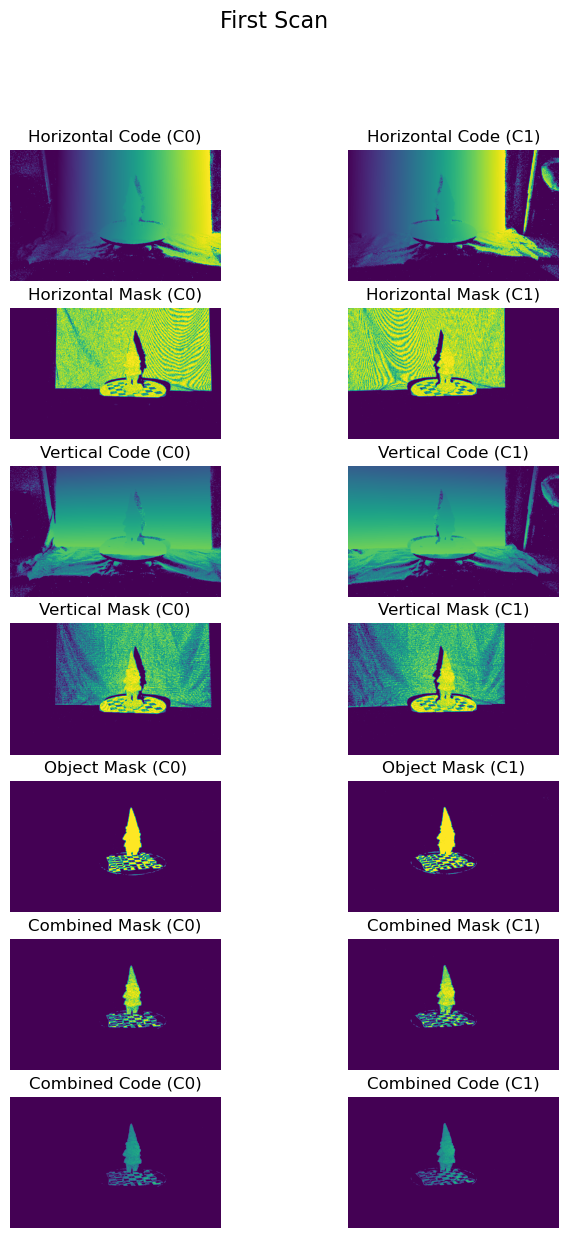

In [6]:
C0, C1, M0, M1 = get_masked_code("./david/grab_0", 0.005, 0.15, display=True)

### Reconstruction

In [7]:
def triangulate(pts2L,camL,pts2R,camR):
    """
    Triangulate the set of points seen at location pts2L / pts2R in the
    corresponding pair of cameras. Return the 3D coordinates relative
    to the global coordinate system


    Parameters
    ----------
    pts2L : 2D numpy.array (dtype=float)
        Coordinates of N points stored in a array of shape (2,N) seen from camL camera

    pts2R : 2D numpy.array (dtype=float)
        Coordinates of N points stored in a array of shape (2,N) seen from camR camera

    camL : Camera
        The first "left" camera view

    camR : Camera
        The second "right" camera view

    Returns
    -------
    pts3 : 2D numpy.array (dtype=float)
        (3,N) array containing 3D coordinates of the points in global coordinates

    """

    #
    # Your code goes here.  I recommend adding assert statements to check the
    # sizes of the inputs and outputs to make sure they are correct 
    #

    pts3 = np.zeros((3, pts2L.shape[1]))

    for i in range(pts2L.shape[1]):
        qL = np.vstack(((pts2L[:, i].reshape(-1, 1) - camL.c) / camL.f, np.array([[1]])))
        qR = np.vstack(((pts2R[:, i].reshape(-1, 1) - camR.c) / camR.f, np.array([[1]])))
        A = np.hstack((camL.R @ qL, -camR.R @ qR))
        b = camR.t - camL.t
        u = np.linalg.lstsq(A, b, rcond=None)[0]
        
        pL = u[0] * qL
        pR = u[1] * qR
        p1 = camL.R @ pL + camL.t
        p2 = camR.R @ pR + camR.t
        pts3[:, i] = (p1 + p2).flatten() / 2

    return pts3

def reconstruct(img0_path, img1_path, C0, C1, M0, M1, camL, camR):
    """
    Reconstruct the 3D points from the codes C0 and C1 for the left and right cameras.


    Parameters
    ----------
    img0_path : str
        Path to the left camera image

    img1_path : str
        Path to the right camera image

    C0 : 2D numpy.array (dtype=float)
        The codes for the left camera, with shape (H,W)

    C1 : 2D numpy.array (dtype=float)
        The codes for the right camera, with shape (H,W)

    M0 : 2D numpy.array (dtype=bool)
        The mask for the left camera, with shape (H,W)

    M1 : 2D numpy.array (dtype=bool)
        The mask for the right camera, with shape (H,W)

    camL : Camera
        The left camera object containing calibration data

    camR : Camera
        The right camera object containing calibration data


    Returns
    -------
    pts2L : 2D numpy.array (dtype=float)
        The pixel coordinates in the left camera for the matched points, shape (2,N)

    pts2R : 2D numpy.array (dtype=float)
        The pixel coordinates in the right camera for the matched points, shape (2,N)

    pts3 : 2D numpy.array (dtype=float)
        The 3D coordinates of the matched points in the global coordinate system, shape (3,N)
    """
    
    # Find the indices of pixels in the left and right code image that 
    # have matching codes. If there are multiple matches, just
    # choose one arbitrarily.
    _, matchL, matchR = np.intersect1d(C0[M0], C1[M1], return_indices=True)
    
    # Let CL and CR be the flattened arrays of codes for the left and right view
    # Suppose you have computed arrays of indices matchL and matchR so that 
    # CL[matchL[i]] == CR[matchR[i]] for all i.  The code below gives one approach
    # to generating the corresponding pixel coordinates for the matched pixels.

    h,w = C0.shape    
    xx,yy = np.meshgrid(range(w),range(h))
    xxL = xx[M0]
    yyL = yy[M0]
    xxR = xx[M1]
    yyR = yy[M1]
    pts2L = np.vstack((xxL[matchL], yyL[matchL]))
    pts2R = np.vstack((xxR[matchR], yyR[matchR]))
 
    # Now triangulate the points

    pts3 = triangulate(pts2L, camL, pts2R, camR)

    img0 = plt.imread(img0_path)
    img1 = plt.imread(img1_path)

    rgb_values = img0[pts2L[1], pts2L[0]].T
    
    return pts2L, pts2R, pts3, rgb_values

### Getting Extrinsic Parameters

In [8]:
def residuals(pts3,pts2,cam,params):
    """
    Compute the difference between the projection of 3D points by the camera
    with the given parameters and the observed 2D locations

    Parameters
    ----------
    pts3 : 2D numpy.array (dtype=float)
        Coordinates of N points stored in a array of shape (3,N)

    pts2 : 2D numpy.array (dtype=float)
        Coordinates of N points stored in a array of shape (2,N)

    params : 1D numpy.array (dtype=float)
        Camera parameters we are optimizing stored in a vector of shape (6,)

    Returns
    -------
    residual : 1D numpy.array (dtype=float)
        Vector of residual 2D projection errors of size 2*N
        
    """
    cam.update_extrinsics(params)
    pts2proj = cam.project(pts3)

    residual = pts2proj - pts2
    residual = residual.flatten()

    return residual

def calibratePose(pts3,pts2,cam,params_init):
    """
    Calibrate the provided camera by updating R,t so that pts3 projects
    as close as possible to pts2

    Parameters
    ----------
    pts3 : 2D numpy.array (dtype=float)
        Coordinates of N points stored in a array of shape (3,N)

    pts2 : 2D numpy.array (dtype=float)
        Coordinates of N points stored in a array of shape (2,N)

    cam : Camera
        Initial estimate of camera
        
    params_init : 1D numpy.array (dtype=float)
        Initial estimate of camera extrinsic parameters ()
        params[0:3] are the rotation angles, params[3:6] are the translation

    Returns
    -------
    cam : Camera
        Refined estimate of camera with updated R,t parameters
        
    """
    func = lambda params: residuals(pts3,pts2,cam,params)
    new_params = scipy.optimize.leastsq(func,params_init)
    cam.update_extrinsics(new_params[0])
    return cam

In [59]:
fid = open('calibration.pickle','rb')
data = pickle.load(fid)
fid.close()

f = data['f']
c = data['c']

# load in the left and right images and find the coordinates of
# the chessboard corners using OpenCV
imgL = plt.imread('./david/grab_0/color_C0_00_u.png')
imgL = cv2.cvtColor(imgL, cv2.COLOR_BGR2GRAY)
imgL = (imgL * 255).astype(np.uint8)
ret, cornersL = cv2.findChessboardCorners(imgL, (6,6), None)
pts2L = cornersL.squeeze().T

imgR = plt.imread('./david/grab_0/color_C1_00_u.png')
imgR = cv2.cvtColor(imgR, cv2.COLOR_BGR2GRAY)
imgR = (imgR * 255).astype(np.uint8)
ret, cornersR = cv2.findChessboardCorners(imgR, (6,6), None)
pts2R = cornersR.squeeze().T

# generate the known 3D point coordinates of points on the checkerboard in cm
pts3 = np.zeros((3,6*6))
zz,xx = np.meshgrid(np.arange(6),np.arange(6))
pts3[0,:] = 2.8*xx.reshape(1,-1)
pts3[2,:] = 2.8*zz.reshape(1,-1)

# Now use your calibratePose function to get the extrinsic parameters
# for the two images. You may need to experiment with the initialization
# in order to get a good result

camL = Camera(f, c, makerotation(0, 0, 0), np.array([0, 0, 0]))
camR = Camera(f, c, makerotation(0, 0, 0), np.array([0, 0, 0]))

camL_params_init = np.array([0,0,0,0,0,-5])
camR_params_init = np.array([0,0,0,0,0,-5])

camL = calibratePose(pts3,pts2L,camL,camL_params_init)
camR = calibratePose(pts3,pts2R,camR,camR_params_init)

pts2L, pts2R, pts3, rgb = reconstruct("./david/grab_0/color_C0_01_u.png", "./david/grab_0/color_C1_01_u.png", C0, C1, M0, M1, camL, camR)
pts3 = pts3[[2, 1, 0], :]

In [26]:
# Add your visualization code here.  As we have done previously it is good to visualize different
# 2D projections XY, XZ, YZ and well as a 3D version
def visualize(pts3):
    # 4 plots, one 3d view and 3 2d views
    fig = plt.figure()
    fig.set_size_inches(8, 8)
    ax = fig.add_subplot(221)
    ax.set_title('XY View')
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_aspect('equal')
    ax.invert_yaxis()
    ax.scatter(pts3[0,:],pts3[1,:],s=1, c=rgb.T)
    ax = fig.add_subplot(222)
    ax.set_title('XZ View')
    ax.set_xlabel('X')
    ax.set_ylabel('Z')
    ax.set_aspect('equal')
    ax.invert_yaxis()
    ax.scatter(pts3[0,:],pts3[2,:],s=1, c=rgb.T)
    ax = fig.add_subplot(223)
    ax.set_title('ZY View')
    ax.set_xlabel('Z')
    ax.set_ylabel('Y')
    ax.set_aspect('equal')
    ax.invert_yaxis()
    ax.scatter(pts3[2,:],pts3[1,:],s=1, c=rgb.T)
    ax = fig.add_subplot(224, projection='3d')
    ax.set_title('3D View')
    ax.set_xlabel('X')
    ax.set_ylabel('Z')
    ax.set_zlabel('Y')
    ax.scatter(pts3[0,:],pts3[2,:],pts3[1,:],s=1, c=rgb.T)
    ax.set_box_aspect([1,1,1])
    ax.invert_zaxis()
    plt.show()

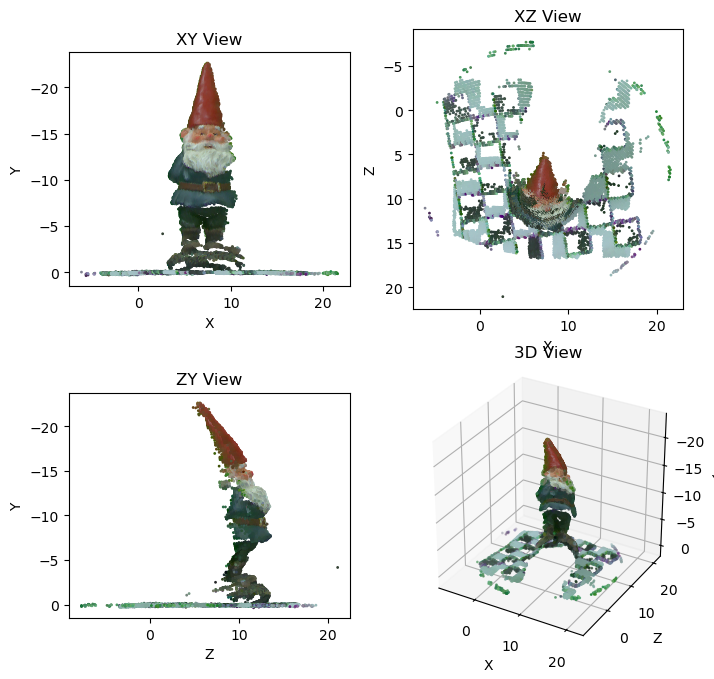

In [60]:
visualize(pts3)